<a href="https://colab.research.google.com/github/spbromberg/ds2002-fa26/blob/main/notebooks/07-visualization/2026-11-13%20%E2%80%94%20Visualization%20Challenge%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

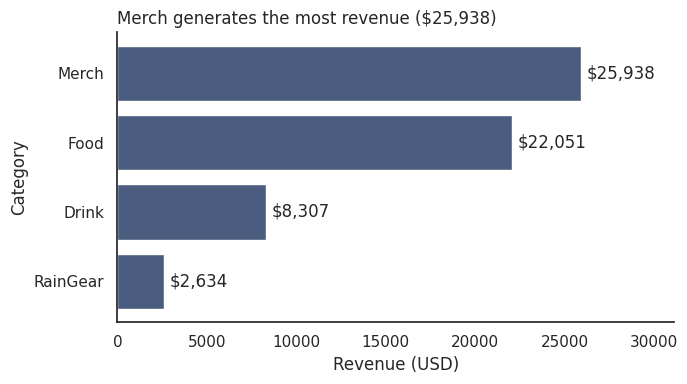

In [2]:
# Add up revenue for each category, then sort so the bars read from low to high.
category_revenue = df.groupby('category')['revenue'].sum().sort_values()

# Find the category with the greatest revenue for the chart's finding title.
top_category = category_revenue.idxmax()
top_revenue = category_revenue.max()

# Create a horizontal bar chart so category names are easy to read.
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(category_revenue.index, category_revenue.values, color=BLUE)

# Add a finding-based title and label both axes with units.
finish(
    ax,
    f'{top_category} generates the most revenue (${top_revenue:,.0f})',
    xlabel='Revenue (USD)',
    ylabel='Category'
)

# Print the exact revenue at the end of each bar.
ax.bar_label(
    bars,
    labels=[f'${value:,.0f}' for value in category_revenue.values],
    padding=4
)

# Start the revenue axis at zero and leave room for the value labels.
ax.set_xlim(0, category_revenue.max() * 1.2)

# Display the completed chart.
plt.show()

**Caption:** Use this comparison to prioritize categories when setting revenue targets; total revenue alone does not show how many orders each category generated.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

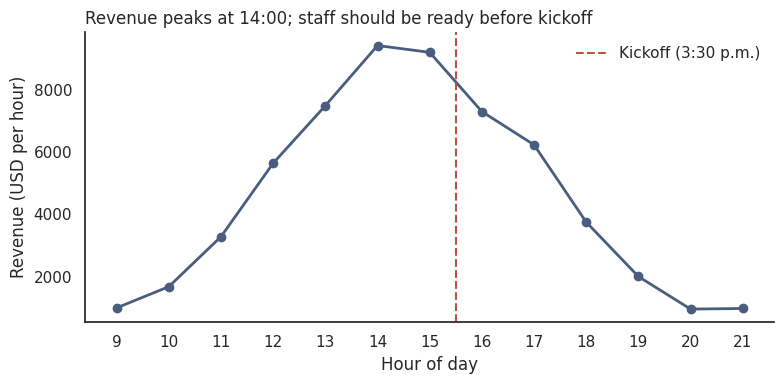

In [3]:
# Sum revenue across all orders for each hour, then sort by hour.
hourly_revenue = df.groupby('hour')['revenue'].sum().sort_index()

# Find the hour with the most revenue for the title.
peak_hour = int(hourly_revenue.idxmax())

# Create a line chart to show how revenue changes over time.
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(
    hourly_revenue.index,
    hourly_revenue.values,
    color=BLUE,
    marker='o',
    linewidth=2
)

# Mark the 3:30 p.m. kickoff time so it can be compared with the revenue peak.
ax.axvline(
    15.5,
    color=RUST,
    linestyle='--',
    label='Kickoff (3:30 p.m.)'
)

# Use the title to state the staffing takeaway; label axes and units.
finish(
    ax,
    f'Revenue peaks at {peak_hour}:00; staff should be ready before kickoff',
    xlabel='Hour of day',
    ylabel='Revenue (USD per hour)'
)

# Show each hour on the x-axis and explain the dashed kickoff line.
ax.set_xticks(hourly_revenue.index)
ax.legend(frameon=False)

# Display the completed chart.
plt.show()

**Caption:** Have staff and sales inventory ready before the afternoon rush. Revenue is being used as a proxy for order activity, and the dashed line marks the 3:30 p.m. kickoff.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

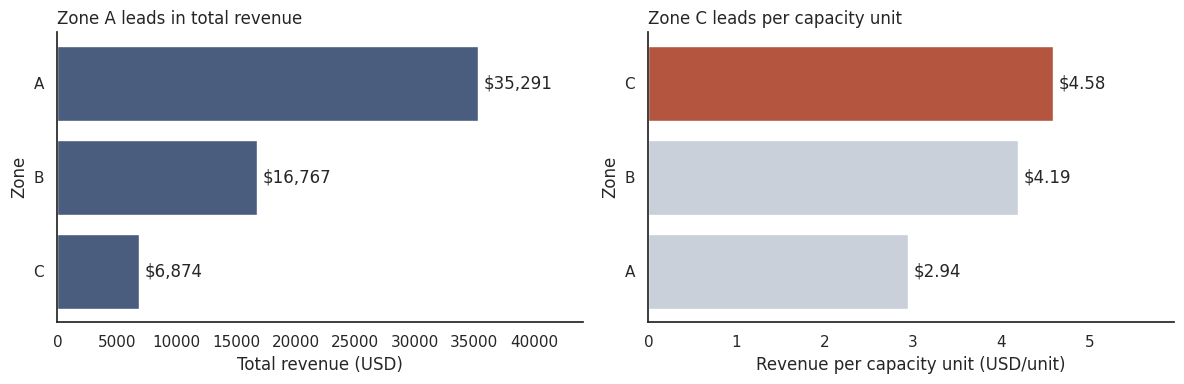

In [4]:
# Sum revenue by zone and align it with the capacity values.
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
raw_revenue = df.groupby('zone')['revenue'].sum().reindex(zone_capacity.keys())
capacity = pd.Series(zone_capacity)

# Divide each zone's revenue by its capacity to create a normalized measure.
revenue_per_capacity = raw_revenue / capacity

# Sort each panel separately so its bars run from low to high.
raw_ordered = raw_revenue.sort_values()
capacity_ordered = revenue_per_capacity.sort_values()

# Find the leader for each measure so the panel titles state the findings.
raw_leader = raw_revenue.idxmax()
capacity_leader = revenue_per_capacity.idxmax()

# Make one panel for total revenue and another for revenue per capacity.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot total revenue by zone.
raw_bars = axes[0].barh(raw_ordered.index, raw_ordered.values, color=BLUE)
finish(
    axes[0],
    f'Zone {raw_leader} leads in total revenue',
    xlabel='Total revenue (USD)',
    ylabel='Zone'
)

# Label the total revenue bars and leave room for those labels.
axes[0].bar_label(
    raw_bars,
    labels=[f'${value:,.0f}' for value in raw_ordered.values],
    padding=4
)
axes[0].set_xlim(0, raw_ordered.max() * 1.25)

# Highlight the zone with the highest revenue per capacity unit.
capacity_colors = [
    RUST if zone == capacity_leader else GRAY
    for zone in capacity_ordered.index
]

# Plot the normalized revenue measure by zone.
capacity_bars = axes[1].barh(
    capacity_ordered.index,
    capacity_ordered.values,
    color=capacity_colors
)
finish(
    axes[1],
    f'Zone {capacity_leader} leads per capacity unit',
    xlabel='Revenue per capacity unit (USD/unit)',
    ylabel='Zone'
)

# Label the normalized bars and leave room for their labels.
axes[1].bar_label(
    capacity_bars,
    labels=[f'${value:,.2f}' for value in capacity_ordered.values],
    padding=4
)
axes[1].set_xlim(0, capacity_ordered.max() * 1.3)

# Adjust spacing so the two panels and their labels fit.
fig.tight_layout()

# Display both panels.
plt.show()

**Caption, and which panel I would present:** The left panel answers which zone generated the most total revenue; the right compares revenue relative to capacity. I would show the right panel when comparing zone productivity, and the left when planning around total sales or revenue.

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

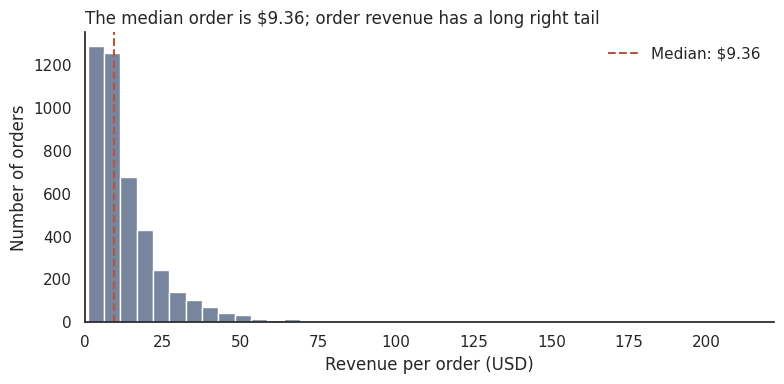

In [5]:
# Calculate the median order revenue so the chart can show a typical order.
median_revenue = df['revenue'].median()

# Create a histogram to show how individual order revenues are distributed.
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x='revenue', bins=40, color=BLUE, ax=ax)

# Mark the median with a dashed line and label it.
ax.axvline(
    median_revenue,
    color=RUST,
    linestyle='--',
    label=f'Median: ${median_revenue:.2f}'
)

# State the distribution's main finding and label both axes with units.
finish(
    ax,
    f'The median order is ${median_revenue:.2f}; order revenue has a long right tail',
    xlabel='Revenue per order (USD)',
    ylabel='Number of orders'
)

# Keep the horizontal axis at zero or above and show what the dashed line means.
ax.set_xlim(left=0)
ax.legend(frameon=False)

# Display the completed chart.
plt.show()

**Caption:** The distribution shows what a typical individual order looks like and reveals the long tail of higher-value orders, which category totals hide. The median is lower than the mean because some orders are much larger than most.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

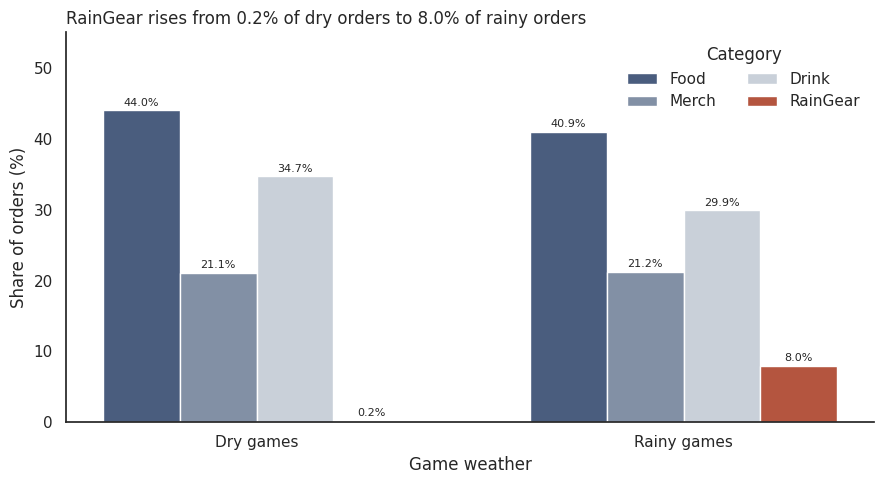

In [6]:
# Count orders for each category within each weather condition.
weather_counts = (
    df.groupby(['weather', 'category'])
      .size()
      .unstack(fill_value=0)
)

# Convert counts to percentages so dry and rainy games can be compared fairly.
weather_share = weather_counts.div(
    weather_counts.sum(axis=1),
    axis=0
) * 100

# Set a consistent order for the weather groups and categories.
weather_order = ['dry', 'rain']
categories = ['Food', 'Merch', 'Drink', 'RainGear']

# Use one color per category, highlighting RainGear in rust.
colors = {
    'Food': BLUE,
    'Merch': '#8290a5',
    'Drink': GRAY,
    'RainGear': RUST
}

# Calculate RainGear's share of orders in each weather group for the title.
dry_raingear_share = weather_share.loc['dry', 'RainGear']
rain_raingear_share = weather_share.loc['rain', 'RainGear']

# Create positions for the two weather groups on the x-axis.
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(weather_order))
width = 0.18

# Draw one bar per category in each weather group.
for i, category in enumerate(categories):
    values = [weather_share.loc[weather, category] for weather in weather_order]
    positions = x + (i - 1.5) * width

    bars = ax.bar(
        positions,
        values,
        width,
        label=category,
        color=colors[category]
    )

    # Label each bar with its percentage.
    ax.bar_label(
        bars,
        labels=[f'{value:.1f}%' for value in values],
        padding=2,
        fontsize=8
    )

# State the RainGear finding in the title and label the axes.
finish(
    ax,
    f'RainGear rises from {dry_raingear_share:.1f}% of dry orders '
    f'to {rain_raingear_share:.1f}% of rainy orders',
    xlabel='Game weather',
    ylabel='Share of orders (%)'
)

# Replace numeric x-axis positions with readable weather labels.
ax.set_xticks(x, ['Dry games', 'Rainy games'])

# Set the y-axis to start at zero and leave space above the tallest bar labels.
ax.set_ylim(0, weather_share.max().max() * 1.25)

# Identify the bar colors with a compact legend.
ax.legend(title='Category', frameon=False, ncol=2)

# Display the completed chart.
plt.show()

**Caption:** RainGear makes up a much larger share of orders on rainy games, supporting extra RainGear inventory for wet weather. There are only two games in each weather group, so treat this as a directional pattern rather than a precise forecast.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [7]:
# Score each chart against the six rubric criteria.
# Each score() call prints the pass/fail result for every criterion.
scores = {
    'chart 1 (category)': score(
        title=True, axes=True, chart_type=True,
        scale=True, readable=True, ink=True
    ),
    'chart 2 (hour)': score(
        title=True, axes=True, chart_type=True,
        scale=True, readable=True, ink=True
    ),
    'chart 3 (zone)': score(
        title=True, axes=True, chart_type=True,
        scale=True, readable=True, ink=True
    ),
    'chart 4 (distribution)': score(
        title=True, axes=True, chart_type=True,
        scale=True, readable=True, ink=True
    ),
    'chart 5 (your choice)': score(
        title=True, axes=True, chart_type=True,
        scale=True, readable=True, ink=True
    ),
}

# Print a compact summary of each chart's score.
print('\nSummary')
for name, value in scores.items():
    status = 'fix' if value < 5 else 'ok'
    print(f'{name:<26} {value}/6  [{status}]')

# Calculate and print the average score across all five charts.
print(f'\naverage: {sum(scores.values()) / len(scores):.1f}/6')

PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6

Summary
chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok]
chart 4 (distribution)     6/6  [ok]
chart 5 (your

### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

a) Chart 3 changed my view of the zones. Zone A generated the most total revenue, but comparing revenue per unit of capacity makes Zone C look strongest. Total revenue and productivity answer different questions.

b) I would show total revenue when a manager needs to plan around sales dollars by zone. I would show revenue per capacity unit when comparing how effectively zones use their capacity. The capacity-normalized view does not show costs or profit, and this sample includes only four games, so I would use it as a comparison rather than a standalone expansion decision.